# Imports

In [2]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np 
import scipy.stats as stats #(not in environment yet?)
import sys
from statsmodels.stats.multicomp import pairwise_tukeyhsd #(not in envirnoment yet)

# Loading Data
Loading one single datafile using pandas, concatenatin all data files into one big table to analyse together

## Looping over all datafiles and concatenating them

In [3]:
# how can I concatenate all files within a certain folder path without loading a single file first

behav_data_path = "/mnt/home/bielefeldt/MPIB-SRT/879-multieyetem/behavioural_outputfiles"
sys.path.append(behav_data_path)

df_list = []
for file_name in os.listdir(behav_data_path):
    if file_name.endswith(".txt") and "pr.txt" not in file_name and not file_name.startswith("resultfile_pil"):  # Check if the file has .txt extension
        file_path = os.path.join(behav_data_path, file_name)
  
        # Read the file and determine whether to skip rows based on numerical content
        data = pd.read_table(file_path, skipinitialspace=True)
        has_numerical_content = data.applymap(lambda x: isinstance(x, (int, float))).any(axis=1)
        
        # Exclude rows with no numerical content
        data = data[has_numerical_content]
        
        df_list.append(data)

# Concatenate all DataFrames in the list
df = pd.concat(df_list, ignore_index=True)

## Binomial Tests of Accuracy

In [4]:
# Binomtest instead of binom_test

# Get unique participant IDs
partis = df['subID'].unique()

# Set the assumed accuracy (expected proportion)
expected_proportion = 0.5

# Set your significance level
alpha = 0.05

# Create a list to store results
results = []

## data to be exlccluded and other info:
# VHG934 missing in data
# which data to exclude because of version and triggers missing?
# Loop over each participant
for i in partis:
    # Get the data for the current participant
    participant_data = df.loc[df['subID'] == i, 'acc_trial_concrete_cued']

    # Calculate the mean accuracy for the current participant
    mean_per_pp = participant_data.mean()
    
    # Count the correct responses for the current participant
    correct_responses = sum(participant_data)

    trials = len(participant_data)
  
    # can maybe not use the p = anymore because the result of the new binomtest (instead of binom_test) is a variable of the type "BinomTestResult", which has all statical values in it. Maybe I can then just omit the 
    # results.append and also maybe omit the empty results matrix at the top
    binom_results = stats.binomtest(correct_responses, trials, p=expected_proportion)
    k = binom_results.k
    n = binom_results.n
    p_value = binom_results.pvalue
    # print(binomresults)
    # print(binomresults.pvalue)
    # Store the results in a tuple (participant ID, mean accuracy, p-value)
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

# Print or analyze the results
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    print(f"Participant {participant_id}:")
    print(f"  Mean Accuracy = {mean_accuracy:.4f}")
    print(f"  Correct Responses = {correct_responses} out of {n}")
    print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
    print("  Interpretation:", end=" ")
    
    # Determine if the result is significant based on your alpha level
    if p_value < alpha:
        print("Significant")
    else:
        print("Not Significant")

result_len = 0
## List of the ones to be excluded
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    if p_value > 0.05:
        result_len = result_len + 1
        print(f"Participant {participant_id}:")
        print(f"  Mean Accuracy = {mean_accuracy:.4f}")
        print(f"  Correct Responses = {correct_responses} out of {n}")
        print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
        print("  Interpretation:", end=" ")
        
        # Determine if the result is significant based on your alpha level
        if p_value < alpha:
            print("Significant")
        else:
            print("Not Significant")
print(f'There were {result_len} elements in the results')

# In this case the result means that a participant that is not significant is not significantly different from the expected proportion or from chance level. They performed not better than chance level. However this would mean that performing significantly worse than chance level would not be exlcluded either


Participant Z16JQR:
  Mean Accuracy = 0.7934
  Correct Responses = 457 out of 576
  Binomial Test (k=457, n=576, p-value=0.0000)
  Interpretation: Significant
Participant C9A31N:
  Mean Accuracy = 0.6806
  Correct Responses = 392 out of 576
  Binomial Test (k=392, n=576, p-value=0.0000)
  Interpretation: Significant
Participant LPULPG:
  Mean Accuracy = 0.8142
  Correct Responses = 469 out of 576
  Binomial Test (k=469, n=576, p-value=0.0000)
  Interpretation: Significant
Participant R8CW7K:
  Mean Accuracy = 0.8003
  Correct Responses = 461 out of 576
  Binomial Test (k=461, n=576, p-value=0.0000)
  Interpretation: Significant
Participant D62XJG:
  Mean Accuracy = 0.7118
  Correct Responses = 410 out of 576
  Binomial Test (k=410, n=576, p-value=0.0000)
  Interpretation: Significant
Participant XXRRPP:
  Mean Accuracy = 0.6458
  Correct Responses = 372 out of 576
  Binomial Test (k=372, n=576, p-value=0.0000)
  Interpretation: Significant
Participant ZGV9KP:
  Mean Accuracy = 0.7188
 

### Binomial Test Condition 1

In [5]:
# Binomtest instead of binom_test

# Get unique participant IDs
partis = df['subID'].unique()

# Set the assumed accuracy (expected proportion)
expected_proportion = 0.5

# Set your significance level
alpha = 0.05

# Create a list to store results
results = []

## data to be exlccluded and other info:
# VHG934 missing in data
# which data to exclude because of version and triggers missing?
# Loop over each participant
for i in partis:
    # Get the data for the current participant
    participant_data1 = df.loc[(df['subID'] == i) & (df['items_presented'] == 1), 'acc_trial_concrete_cued']

    # Calculate the mean accuracy for the current participant
    mean_per_pp = participant_data1.mean()
    
    # Count the correct responses for the current participant
    correct_responses = sum(participant_data1)

    trials = len(participant_data1)
  
    # can maybe not use the p = anymore because the result of the new binomtest (instead of binom_test) is a variable of the type "BinomTestResult", which has all statical values in it. Maybe I can then just omit the 
    # results.append and also maybe omit the empty results matrix at the top
    binom_results = stats.binomtest(correct_responses, trials, p=expected_proportion, )
    k = binom_results.k
    n = binom_results.n
    p_value = binom_results.pvalue
    # print(binomresults)
    # print(binomresults.pvalue)
    # Store the results in a tuple (participant ID, mean accuracy, p-value)
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

# Print or analyze the results
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    print(f"Participant {participant_id}:")
    print(f"  Mean Accuracy = {mean_accuracy:.4f}")
    print(f"  Correct Responses = {correct_responses} out of {n}")
    print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
    print("  Interpretation:", end=" ")
    
    # Determine if the result is significant based on your alpha level
    if p_value < alpha:
        print("Significant")
    else:
        print("Not Significant")

result_len = 0
## List of the ones to be excluded
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    if p_value > 0.05:
        result_len = result_len + 1
        print(f"Participant {participant_id}:")
        print(f"  Mean Accuracy = {mean_accuracy:.4f}")
        print(f"  Correct Responses = {correct_responses} out of {n}")
        print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
        print("  Interpretation:", end=" ")
        
        # Determine if the result is significant based on your alpha level
        if p_value < alpha:
            print("Significant")
        else:
            print("Not Significant")
print(f'There were {result_len} elements in the results')

# In this case the result means that a participant that is not significant is not significantly different from the expected proportion or from chance level. They performed not better than chance level. However this would mean that performing significantly worse than chance level would not be exlcluded either


Participant Z16JQR:
  Mean Accuracy = 0.8385
  Correct Responses = 161 out of 192
  Binomial Test (k=161, n=192, p-value=0.0000)
  Interpretation: Significant
Participant C9A31N:
  Mean Accuracy = 0.7292
  Correct Responses = 140 out of 192
  Binomial Test (k=140, n=192, p-value=0.0000)
  Interpretation: Significant
Participant LPULPG:
  Mean Accuracy = 0.8958
  Correct Responses = 172 out of 192
  Binomial Test (k=172, n=192, p-value=0.0000)
  Interpretation: Significant
Participant R8CW7K:
  Mean Accuracy = 0.9010
  Correct Responses = 173 out of 192
  Binomial Test (k=173, n=192, p-value=0.0000)
  Interpretation: Significant
Participant D62XJG:
  Mean Accuracy = 0.8125
  Correct Responses = 156 out of 192
  Binomial Test (k=156, n=192, p-value=0.0000)
  Interpretation: Significant
Participant XXRRPP:
  Mean Accuracy = 0.7708
  Correct Responses = 148 out of 192
  Binomial Test (k=148, n=192, p-value=0.0000)
  Interpretation: Significant
Participant ZGV9KP:
  Mean Accuracy = 0.8229
 

### Binomial Test Condition 2

In [6]:
# Binomtest instead of binom_test

# Get unique participant IDs
partis = df['subID'].unique()

# Set the assumed accuracy (expected proportion)
expected_proportion = 0.5

# Set your significance level
alpha = 0.05

# Create a list to store results
results = []

## data to be exlccluded and other info:
# VHG934 missing in data
# which data to exclude because of version and triggers missing?
# Loop over each participant
for i in partis:
    # Get the data for the current participant
    participant_data2 = df.loc[(df['subID'] == i) & (df['items_presented'] == 2), 'acc_trial_concrete_cued']

    # Calculate the mean accuracy for the current participant
    mean_per_pp = participant_data2.mean()
    
    # Count the correct responses for the current participant
    correct_responses = sum(participant_data2)

    trials = len(participant_data2)
  
    # can maybe not use the p = anymore because the result of the new binomtest (instead of binom_test) is a variable of the type "BinomTestResult", which has all statical values in it. Maybe I can then just omit the 
    # results.append and also maybe omit the empty results matrix at the top
    binom_results = stats.binomtest(correct_responses, trials, p=expected_proportion, )
    k = binom_results.k
    n = binom_results.n
    p_value = binom_results.pvalue
    # print(binomresults)
    # print(binomresults.pvalue)
    # Store the results in a tuple (participant ID, mean accuracy, p-value)
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

# # Print or analyze the results
# for result in results:
#     participant_id, mean_accuracy, correct_responses, k, n, p_value = result
#     print(f"Participant {participant_id}:")
#     print(f"  Mean Accuracy = {mean_accuracy:.4f}")
#     print(f"  Correct Responses = {correct_responses} out of {n}")
#     print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
#     print("  Interpretation:", end=" ")
    
#     # Determine if the result is significant based on your alpha level
#     if p_value < alpha:
#         print("Significant")
#     else:
#         print("Not Significant")

result_len = 0
## List of the ones to be excluded
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    if p_value > 0.05:
        result_len = result_len + 1
        print(f"Participant {participant_id}:")
        print(f"  Mean Accuracy = {mean_accuracy:.4f}")
        print(f"  Correct Responses = {correct_responses} out of {n}")
        print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
        print("  Interpretation:", end=" ")
        
        # Determine if the result is significant based on your alpha level
        if p_value < alpha:
            print("Significant")
        else:
            print("Not Significant")
print(f'There were {result_len} elements in the results')

# In this case the result means that a participant that is not significant is not significantly different from the expected proportion or from chance level. They performed not better than chance level. However this would mean that performing significantly worse than chance level would not be exlcluded either


Participant OUGX64:
  Mean Accuracy = 0.5156
  Correct Responses = 99 out of 192
  Binomial Test (k=99, n=192, p-value=0.7183)
  Interpretation: Not Significant
Participant 6TQVJE:
  Mean Accuracy = 0.5677
  Correct Responses = 109 out of 192
  Binomial Test (k=109, n=192, p-value=0.0709)
  Interpretation: Not Significant
Participant 30K8XE:
  Mean Accuracy = 0.5521
  Correct Responses = 106 out of 192
  Binomial Test (k=106, n=192, p-value=0.1701)
  Interpretation: Not Significant
There were 3 elements in the results


### Binomial Test Condition 3

In [7]:
# Binomtest instead of binom_test

# Get unique participant IDs
partis = df['subID'].unique()

# Set the assumed accuracy (expected proportion)
expected_proportion = 0.5

# Set your significance level
alpha = 0.05

# Create a list to store results
results = []

## data to be exlccluded and other info:
# VHG934 missing in data
# which data to exclude because of version and triggers missing?
# Loop over each participant
for i in partis:
    # Get the data for the current participant
    participant_data3 = df.loc[(df['subID'] == i) & (df['items_presented'] == 3), 'acc_trial_concrete_cued']

    # Calculate the mean accuracy for the current participant
    mean_per_pp = participant_data3.mean()
    
    # Count the correct responses for the current participant
    correct_responses = sum(participant_data3)

    trials = len(participant_data3)
  
    # can maybe not use the p = anymore because the result of the new binomtest (instead of binom_test) is a variable of the type "BinomTestResult", which has all statical values in it. Maybe I can then just omit the 
    # results.append and also maybe omit the empty results matrix at the top
    binom_results = stats.binomtest(correct_responses, trials, p=expected_proportion, )
    k = binom_results.k
    n = binom_results.n
    p_value = binom_results.pvalue
    # print(binomresults)
    # print(binomresults.pvalue)
    # Store the results in a tuple (participant ID, mean accuracy, p-value)
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

# Print or analyze the results
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    print(f"Participant {participant_id}:")
    print(f"  Mean Accuracy = {mean_accuracy:.4f}")
    print(f"  Correct Responses = {correct_responses} out of {n}")
    print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
    print("  Interpretation:", end=" ")
    
    # Determine if the result is significant based on your alpha level
    if p_value < alpha:
        print("Significant")
    else:
        print("Not Significant")

result_len = 0
## List of the ones to be excluded
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    if p_value > 0.05:
        result_len = result_len + 1
        print(f"Participant {participant_id}:")
        print(f"  Mean Accuracy = {mean_accuracy:.4f}")
        print(f"  Correct Responses = {correct_responses} out of {n}")
        print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
        print("  Interpretation:", end=" ")
        
        # Determine if the result is significant based on your alpha level
        if p_value < alpha:
            print("Significant")
        else:
            print("Not Significant")
print(f'There were {result_len} elements in the results')

# In this case the result means that a participant that is not significant is not significantly different from the expected proportion or from chance level. They performed not better than chance level. However this would mean that performing significantly worse than chance level would not be exlcluded either

Participant Z16JQR:
  Mean Accuracy = 0.7448
  Correct Responses = 143 out of 192
  Binomial Test (k=143, n=192, p-value=0.0000)
  Interpretation: Significant
Participant C9A31N:
  Mean Accuracy = 0.6354
  Correct Responses = 122 out of 192
  Binomial Test (k=122, n=192, p-value=0.0002)
  Interpretation: Significant
Participant LPULPG:
  Mean Accuracy = 0.7708
  Correct Responses = 148 out of 192
  Binomial Test (k=148, n=192, p-value=0.0000)
  Interpretation: Significant
Participant R8CW7K:
  Mean Accuracy = 0.7135
  Correct Responses = 137 out of 192
  Binomial Test (k=137, n=192, p-value=0.0000)
  Interpretation: Significant
Participant D62XJG:
  Mean Accuracy = 0.6354
  Correct Responses = 122 out of 192
  Binomial Test (k=122, n=192, p-value=0.0002)
  Interpretation: Significant
Participant XXRRPP:
  Mean Accuracy = 0.5573
  Correct Responses = 107 out of 192
  Binomial Test (k=107, n=192, p-value=0.1294)
  Interpretation: Not Significant
Participant ZGV9KP:
  Mean Accuracy = 0.67

## Excluding Participants

In [8]:
# List of subject IDs to exclude
subjects_to_exclude = ['OUGX64']

# Use boolean indexing to drop rows where 'subID' is in the exclusion list
df = df[~df['subID'].isin(subjects_to_exclude)]

## Adding Columns for later use

### Adding Column for mask

In [9]:
df['mask'] = 0

df.loc[df['onset_mask'].notna() & (df['onset_mask'] > 0), 'mask'] = 1

### Adding Column for Button Press

In [10]:
# There are no NANs in the button press column. What happens when no button was pressed? Probably they just get an inaccurate but this would not be seen in the data, without the trigger there would be no way of knowing whether it was inaccurate because no button was pressed or even though a button was pressed


# Calculate 'correct_rot_response'
df['correct_rot_response'] = df['object_cued_rot'] - df['object_test_rot_cued']

# Adding the new column with 0 and 1 values based on conditions
df['button_press_clockwise'] = 0  # Initialize with 0
# if the correct response is clockwise and the person was correct -> clockwise button press
df.loc[(df['correct_rot_response'] > 0) & (df['acc_trial_concrete_cued'] > 0), 'button_press_clockwise'] = 1
# if the correct response is anticlockwise and the person was not correct -> clockwise button press
df.loc[(df['correct_rot_response'] < 0) & (df['acc_trial_concrete_cued'] == 0), 'button_press_clockwise'] = 1

### Adding column for stimuli subset

In [11]:
# Define the stimuli sets
stimuli_set1 = ['01_pitcher02a_BOSS.jpg', '01_lighthouse.jpg', '01_table03.jpg']
stimuli_set2 = ['02_crown.jpg', '02_candelabra.jpg', '02_photoshopTelephone.jpg']
stimuli_set3 = ['03_gazebo.jpg', '03_radio03a.jpg', '03_lamppost01.jpg']

# Function to determine the stimuli set based on 'object_1_name'
def determine_stimuli_set(row):
    object_name = row['object_1_name']
    if object_name in stimuli_set1:
        return 'stimuli_set1'
    elif object_name in stimuli_set2:
        return 'stimuli_set2'
    elif object_name in stimuli_set3:
        return 'stimuli_set3'
    else:
        return 'Unknown'  # You can change this to whatever value you prefer for other cases

# Use the apply() method to create the 'stimuli_set' column
df['stimuli_set'] = df.apply(determine_stimuli_set, axis=1)

### Column names as variables

In [12]:
columns = df.columns
column_names = df.columns.tolist()

# Descriptive Statistics

In [13]:
# Number of participants after exclusion
good_partis = df['subID'].unique()
len_partis = len(good_partis)
print(f'There were {len_partis} participants in the dataset that went into the final analysis.')

# Gender
# Group the DataFrame by sub_ID and get the first occurrence of sub_gender in each group
gender_by_sub_id = df.groupby('subID')['sub_gender'].first()

# Count the instances of 'M' within the grouped sub_gender data
gender_counts = gender_by_sub_id.value_counts()
if 'M' in gender_counts:
    count_of_males = gender_counts['M']
    print(f"Count of male Participants: {count_of_males}")

# Calculate the proportion
gender_propo = count_of_males / len(good_partis)
print('Proportion of male participants:', gender_propo)

# age
age_by_sub_id = df.groupby('subID')['sub_age'].first()
mean_age = age_by_sub_id.mean()
print(f'The mean age of participants was: {mean_age}')

# number of participants with and without mask
masked_pp = df.groupby('subID')['mask'].first()
mask_counts = masked_pp.value_counts()
print(f"There were {mask_counts[1]} Participants that had the Version of the task including the mask and {mask_counts[0]} without the mask.")

# number of participants per stimuli set
stimset_pp = df.groupby('subID')['stimuli_set'].first()
stimset_counts = stimset_pp.value_counts()
print(f"There were {stimset_counts['stimuli_set1']} Participants tested with stimuli set 1, {stimset_counts['stimuli_set2']} with stimuli set 2, and {stimset_counts['stimuli_set3']} with stimuli set 3.")

There were 42 participants in the dataset that went into the final analysis.
Count of male Participants: 12
Proportion of male participants: 0.2857142857142857
The mean age of participants was: 25.30952380952381
There were 20 Participants that had the Version of the task including the mask and 22 without the mask.
There were 15 Participants tested with stimuli set 1, 14 with stimuli set 2, and 13 with stimuli set 3.


# Confidence / Manipulation / Accuracy Checks

In [14]:
# check wether condition makes it harder (it should)

# checking accuracy between upright and upside-down might also count as a manipulation check

# generally check if accuracy is good enough (when is it significantly above chance?)

## Mask vs. No Mask 

In [15]:
# Mask vs no Mask
mask_data = df.loc[df['mask'] == 1, 'acc_trial_concrete_cued']
nomask_data = df.loc[df['mask'] == 0, 'acc_trial_concrete_cued']

# Perform two-sample independent t-test
t_statistic, p_value = stats.ttest_ind(mask_data, nomask_data)

# Define the significance level (alpha)
alpha = 0.05

# Print the t-test results
print("T-Test Results:")
print("T-statistic:", t_statistic)
print("p-value:", p_value)

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between the mask version and the no-mask version.")
else:
    print("The t-test does not indicate a significant difference in accuracy between the mask verision and the no-mask version.")


T-Test Results:
T-statistic: 1.955740662662708
p-value: 0.05050720629259939
The t-test does not indicate a significant difference in accuracy between the mask verision and the no-mask version.


In [16]:
# accuracy for position of item within the load conditions (mnemonic distance?, in position two and three they should be remembered better)

## Upside down vs upright accuracy

In [17]:

# these give a boolean value (True/False)

#ud = (ud <= 270 and ud >= 90)
upside_down = (df['object_test_rot_cued'] < 270) & (df['object_test_rot_cued'] > 90)
upright = (df['object_test_rot_cued'] < 90) | (df['object_test_rot_cued'] > 270)
#upside_down = df['object_test_rot_cued'] ('object_test_rot_cued' <= 270) and ('object_test_rot_cued' >= 90)
# could probably do with only one variable and just check wether its true or false
# 180° is not the upright position necessarily, where does the circle start?
#upright = df['object_test_rot_cued'] == ud = (ud <= 270 and ud >= 90)

# might have to be upright= true or something

mean_upside_down = df.loc[upside_down, 'acc_trial_concrete_cued'].mean()
mean_upright = df.loc[upright, 'acc_trial_concrete_cued'].mean()
print(mean_upright)
print(mean_upside_down)


# Perform two-sample independent t-test
t_statistic, p_value = stats.ttest_ind(upside_down, upright)

# Define the significance level (alpha)
alpha = 0.05

# Print the t-test results
print("T-Test Results:")
print("T-statistic:", t_statistic)
print("p-value:", p_value)

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between upright and upside-down probe items.")
else:
    print("The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.")



0.7261963901308164
0.7067855373947499
T-Test Results:
T-statistic: 0.32732043251039145
p-value: 0.7434269560871095
The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.


## Mean accuracy by condition, oneway ANOVA

### Assumtions met?!

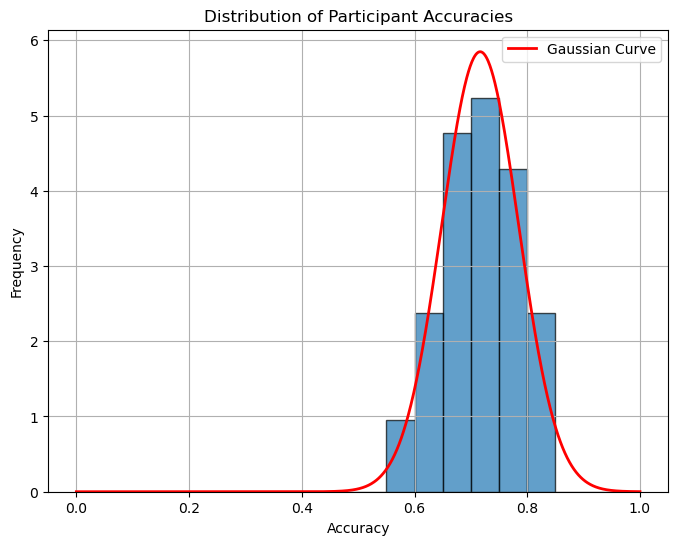

In [18]:
accuracy_per_participant = df.groupby('subID')['acc_trial_concrete_cued'].mean()
accuracy_range = (0, 1)

plt.figure(figsize=(8, 6))  # Set the figure size
# Create the histogram
hist, bins, _ = plt.hist(accuracy_per_participant, bins=20, range=accuracy_range, edgecolor='k', alpha=0.7, density=True)

# Calculate the mean and standard deviation of the data
mean = np.mean(accuracy_per_participant)
std_dev = np.std(accuracy_per_participant)

# Create a range of x values for the Gaussian curve
x = np.linspace(accuracy_range[0], accuracy_range[1], 1000)

# Calculate the corresponding y values for the Gaussian curve
y = stats.norm.pdf(x, mean, std_dev)

# Plot the Gaussian curve
plt.plot(x, y, 'r-', lw=2, label='Gaussian Curve')

# Add labels and a title
plt.xlabel('Accuracy')
plt.ylabel('Frequency')
plt.title('Distribution of Participant Accuracies')

# Show gridlines (optional)
plt.grid(True)

# Add a legend
plt.legend()

# Show the plot
plt.show()

In [19]:

# does all three conditions in one and groups them by 'items_presented' which is the condition (can add .values at the end if I want only the answer values)
mean_cond = df.groupby('items_presented')['acc_trial_concrete_cued'].mean()
print(mean_cond)
mean_acc = df['acc_trial_concrete_cued'].mean()
print(mean_acc)

condition_means = mean_cond.tolist()
condition_labels = ['1', '2', '3']
# these turn out to be exactly the same size, I am a little suspicious that I indeed have exactly the same number of accuracy lines for every condition
# can remove this later, but might be interesting to check the number of samples per condition after I decide which participants to exclude
# len_sample_con1 = len(df[df['items_presented'] == 1])
# print('samples con1:', len_sample_con1)
# len_sample_con2 = len(df[df['items_presented'] == 2])
# print('samples con1:', len_sample_con2)
# len_sample_con3 = len(df[df['items_presented'] == 3])
# print('samples con1:', len_sample_con3)

acc_con1 = df.loc[df['items_presented'] == 1, 'acc_trial_concrete_cued']
acc_con2 = df.loc[df['items_presented'] == 2, 'acc_trial_concrete_cued']
acc_con3 = df.loc[df['items_presented'] == 3, 'acc_trial_concrete_cued']

# Perform one-way ANOVA
f_statistic, p_value = stats.f_oneway(acc_con1, acc_con2, acc_con3)

# Define the significance level (alpha)
alpha = 0.05

# Print the ANOVA results
print("ANOVA Results:")
print("F-statistic:", f_statistic)
print("p-value:", p_value)

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The one-way ANOVA indicates a significant difference among the three conditions.")
else:
    print("The one-way ANOVA does not indicate a significant difference among the three conditions.")

items_presented
1    0.798363
2    0.694568
3    0.656498
Name: acc_trial_concrete_cued, dtype: float64
0.7164765211640212
ANOVA Results:
F-statistic: 207.12468139583711
p-value: 6.433665234597769e-90
The one-way ANOVA indicates a significant difference among the three conditions.


In [20]:
# Mnemonic distance + accuracy

## Accuraccy over time 

block_number
1     0.657407
2     0.668651
3     0.698413
4     0.695767
5     0.716270
6     0.703704
7     0.722222
8     0.750661
9     0.709656
10    0.744048
11    0.730820
12    0.732804
13    0.734788
14    0.720899
15    0.742725
16    0.734788
Name: acc_trial_concrete_cued, dtype: float64


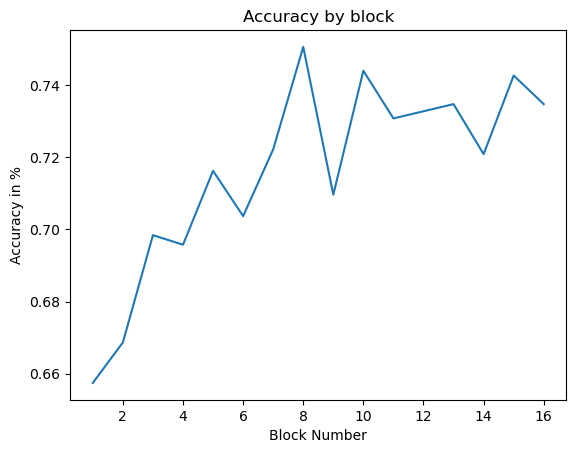

In [21]:
# (block by block, do they get better or worse)
# plots using matplotlib
# THIS DOES NOT SEEM TO WORK

#image = plt.imshow(mean_block_allp) #-> heatmap

# ave_plot = matplotlib.pyplot.plot(ave_inflammation) -> general x/y plot
mean_block_allp = df.groupby('block_number')['acc_trial_concrete_cued'].mean()
print(mean_block_allp)
#df_sorted = df.sort_values(by='trial')
#print(df_sorted)
acc_by_block = plt.plot(mean_block_allp)
plt.xlabel('Block Number')  # Set the label for the x-axis
plt.ylabel('Accuracy in %')  # Set the label for the y-axis
plt.title('Accuracy by block')  # Set the title for the plot
plt.show()  # Display the plot

### Add Anova to test if they significantly got better over time


# Circular Stuff

## Oblique Effect

### two categories (oblique vs cardinal)

object_cued_rot
11.25     0.757051
33.75     0.741176
56.25     0.674357
78.75     0.723077
101.25    0.719918
123.75    0.676607
146.25    0.698444
168.75    0.725375
191.25    0.724967
213.75    0.709530
236.25    0.690085
258.75    0.709827
281.25    0.748815
303.75    0.682155
326.25    0.711097
348.75    0.771294
Name: acc_trial_concrete_cued, dtype: float64
mean per category:  Cardinal_Category
Cardinal    0.735101
Oblique     0.698051
Name: acc_trial_concrete_cued, dtype: float64
grouped data: object_cued_rot  Cardinal_Category
11.25            Cardinal             0.757051
33.75            Oblique              0.741176
56.25            Oblique              0.674357
78.75            Cardinal             0.723077
101.25           Cardinal             0.719918
123.75           Oblique              0.676607
146.25           Oblique              0.698444
168.75           Cardinal             0.725375
191.25           Cardinal             0.724967
213.75           Oblique            

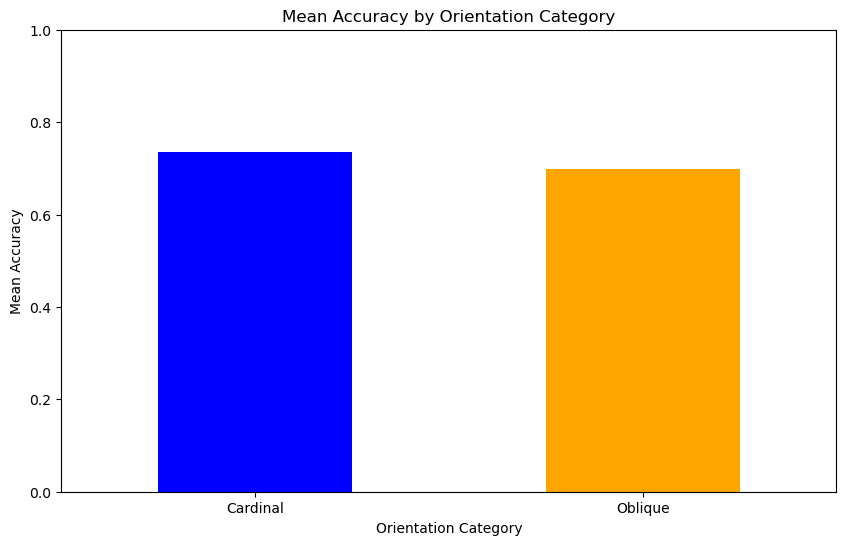

T-Test Results:
T-statistic: 3.3951467176610497
p-value: 0.004354730336419638
The t-test indicates a significant difference in accuracy between cardinal and oblique orientations in probe items.


In [22]:
## Grouping and comparing the data according to two categories: cardinal (8 orientations closest to the cardinal axes) and oblique (remaining 8 diagonal orientations)
mean_per_ori_values = df.groupby('object_cued_rot')['acc_trial_concrete_cued'].mean().values
mean_per_ori = df.groupby('object_cued_rot')['acc_trial_concrete_cued'].mean()
print(mean_per_ori)

# orientations closest to the cardinal axes
orientation_subset_cardinal = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]

# Create a new column to indicate the categories
df['Cardinal_Category'] = df['object_cued_rot'].apply(lambda x: 'Cardinal' if x in orientation_subset_cardinal else 'Oblique')

# Calculate mean accuracy for each category
mean_per_category = df.groupby('Cardinal_Category')['acc_trial_concrete_cued'].mean()
print("mean per category: ", mean_per_category)

# Group data by 'object_cued_rot' and 'Cardinal_Category'
grouped_cardinal = df.groupby(['object_cued_rot', 'Cardinal_Category'])['acc_trial_concrete_cued'].mean()

print("grouped data:", grouped_cardinal)

# Reset index for easier formatting
grouped_cardinal = grouped_cardinal.reset_index()

# Organize data by 'Cardinal' and 'Oblique' categories
cardinal_data = grouped_cardinal[grouped_cardinal['Cardinal_Category'] == 'Cardinal']
oblique_data = grouped_cardinal[grouped_cardinal['Cardinal_Category'] == 'Oblique']



# # Select data for 'Cardinal' category

# # Select data for 'Oblique' category
# oblique_data2 = df.loc[df['Cardinal_Category'] == 'Oblique', 'acc_trial_concrete_cued']

#does the following line work? without df? - yes because it is within a newly stored variable
cardinal_acc = cardinal_data['acc_trial_concrete_cued']
oblique_acc = oblique_data['acc_trial_concrete_cued']

## Visualising the data 
# Create a bar plot using matplotlib
plt.figure(figsize=(10, 6))
mean_per_category.plot(kind='bar', color=['blue', 'orange'])
plt.title("Mean Accuracy by Orientation Category")
plt.xlabel("Orientation Category")
plt.ylabel("Mean Accuracy")
plt.ylim(0, 1)  # Set y-axis limits to match the range of accuracy values
plt.xticks(rotation=0)
plt.show()

# Perform two-sample independent t-test
t_statistic, p_value = stats.ttest_ind(cardinal_acc, oblique_acc)

# Define the significance level (alpha)
alpha = 0.05

# Print the t-test results
print("T-Test Results:")
print("T-statistic:", t_statistic)
print("p-value:", p_value)

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between cardinal and oblique orientations in probe items.")
else:
    print("The t-test does not indicate a significant difference in accuracy between cardinal and oblique orientations in probe items.")

## potentially add significance to the plots (asterix)


MBP: object_cued_rot  items_presented
11.25            1                  0.851190
                 2                  0.718690
                 3                  0.705773
33.75            1                  0.791667
                 2                  0.731225
                 3                  0.701923
56.25            1                  0.785714
                 2                  0.642447
                 3                  0.593878
78.75            1                  0.797619
                 2                  0.731610
                 3                  0.637295
101.25           1                  0.815476
                 2                  0.713978
                 3                  0.629482
123.75           1                  0.734127
                 2                  0.666008
                 3                  0.629259
146.25           1                  0.763889
                 2                  0.701375
                 3                  0.633270
168.75           

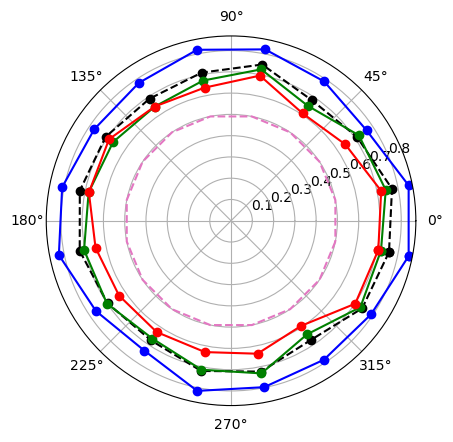

In [26]:
## Plotting the Oblique effect on a polar plot

spacing = np.arange(11.25, 360, 22.5)
spacing_rad = np.radians(spacing)

## change the above line to make it so that positive is going anticlockwise. Apparently theta is always going anticlockwise

# making it a full circle
spacing_circ = np.append(spacing_rad, spacing_rad[0])

acc_per_ori = df.groupby('object_cued_rot')['acc_trial_concrete_cued'].mean().values

acc_df = df.groupby(by=['object_cued_rot', 'items_presented'])['acc_trial_concrete_cued'].mean()
#print(mbp_df)
#-> this output looks right but looking at the variable mbp_df in the data viewer looks weird
# -> this returns a dataframe called mbp_df that is the same size as df but is sorted by object_cued_rot and within each object_cued_rot it is then sorted by items_presented

# seperate by con
oriacc1 = acc_df.loc[acc_df.index.get_level_values('items_presented') == 1].to_numpy()
oriacc2 = acc_df.loc[acc_df.index.get_level_values('items_presented') == 2].to_numpy()
oriacc3 = acc_df.loc[acc_df.index.get_level_values('items_presented') == 3].to_numpy()

print("MBP:", acc_df)
print("MBP1:", oriacc1)
print("MBP2:", oriacc2)
print("MBP3:", oriacc3)

# Create the polar plot
fig = plt.figure()
# maybe change the following line to plt.axes(projection='polar')
ax = fig.add_subplot(111, projection='polar')

#Repeating the last data point to make it a full circle
# mbp_rad = np.append(mbp_rad, mbp_rad[0])
# mbp1_rad = np.append(mbp1_rad, mbp1_rad[0])
# mbp2_rad = np.append(mbp2_rad, mbp2_rad[0])
# mbp3_rad = np.append(mbp3_rad, mbp3_rad[0])

acc_per_ori_circ = np.append(acc_per_ori, acc_per_ori[0])
oriacc1_circ = np.append(oriacc1, oriacc1[0])
oriacc2_circ = np.append(oriacc2, oriacc2[0])
oriacc3_circ = np.append(oriacc3, oriacc3[0])

# Plot the data for the general mbp
ax.plot(-spacing_circ, acc_per_ori_circ, 'ko--')

unbiased_assumption = np.full(17, 0.5)

# # Plot the data for the three conditions individually
# at the moment using -spacing_rad to make the data go in the correct (anticlockwise direction)
ax.plot(-spacing_circ, unbiased_assumption, color='tab:pink', linestyle='dashed')
ax.plot(-spacing_circ, oriacc1_circ, 'bo-')
ax.plot(-spacing_circ, oriacc2_circ, 'go-')
ax.plot(-spacing_circ, oriacc3_circ, 'ro-')


# Set plot attributes (-> labels and shit)
plt.legend
# Show the plot
plt.show()


### 4 categories (A,B,C,D) referring to the four equal distances from cardinal axes

In [ ]:
## Could also do the same and compare the four orientations per quadrant

# mean_per_ori

# # orientations closest to the cardinal axes
# orientation_subset_A = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]
# orientation_subset_B = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]
# orientation_subset_C = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]
# orientation_subset_D = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]



# Define the orientation bins and labels
orientation_bins = {
    11.25: 'Ori Bin A', 33.75: 'Ori Bin B', 56.25: 'Ori Bin C', 78.75: 'Ori Bin D',
    101.25: 'Ori Bin A', 123.75: 'Ori Bin B', 146.25: 'Ori Bin C', 168.75: 'Ori Bin D',
    191.25: 'Ori Bin A', 213.75: 'Ori Bin B', 236.25: 'Ori Bin C', 258.75: 'Ori Bin D',
    281.25: 'Ori Bin A', 303.75: 'Ori Bin B', 326.25: 'Ori Bin C', 348.75: 'Ori Bin D'
}

# Create a new column with bin labels
df['Orientation_Bin'] = df['object_cued_rot'].map(orientation_bins)

## Visualising the data

# Calculate mean accuracy for each bin
mean_accuracies = df.groupby('Orientation_Bin')['acc_trial_concrete_cued'].mean()

# Create a bar plot using matplotlib
plt.figure(figsize=(10, 6))
mean_accuracies.plot(kind='bar', color=['blue', 'green', 'orange', 'red'])
plt.title("Mean Accuracy by Orientation Bin")
plt.xlabel("Orientation Bin")
plt.ylabel("Mean Accuracy")
plt.ylim(0, 1)  # Set y-axis limits to match the range of accuracy values
plt.xticks(rotation=0)
plt.show()

## check if assumptions of ANOVA are met!!!


# Perform ANOVA
anova_results = df.groupby('Orientation_Bin')['acc_trial_concrete_cued'].apply(list)
f_statistic, p_value = stats.f_oneway(*anova_results)

print("F-statistic:", f_statistic)
print("P-value:", p_value)

# Interpret the results
alpha = 0.05
if p_value < alpha:
    print("The p-value is significant, indicating differences between at least two groups.")
else:
    print("The p-value is not significant, indicating no significant differences between groups.")

## could then also insert asterix whereever the data is significantly different

## Cardinal Repulsion

In [ ]:
# mean clockwise proportion of all button presses
# mbp = mean button press 
mbp = df['button_press_clockwise'].mean()
print("the mean of all button presses is:", mbp)

# mean button press per condition (do I already have that somewhere else?)
mbp_per_con = df.groupby('items_presented')['button_press_clockwise'].mean()
print("this is the mbp_per_con:", mbp_per_con)

# mean button press per rotation/ori
mbp_per_ori = df.groupby('object_cued_rot')['button_press_clockwise'].mean().values
print(mbp_per_ori)

#Does it make a difference when sorting this over the orientations of testobjects? Probably shouldnt --- !!! nope not the same for some reason 63 values?!?!?
mean_rot_button_press_testobject = df.groupby('object_test_rot_cued')['button_press_clockwise'].mean().values
print(mean_rot_button_press_testobject)

# this is the same data as visualised in the polar plot and should probably be removed
plt.plot(mbp_per_ori)

plt.xlabel('Orientation (360°)')  # Set the label for the x-axis
plt.ylabel('Proportion of clockwise button presses')  # Set the label for the y-axis
plt.title('Proportion of clockwise button presses per Orientation')  # Set the title for the plot
plt.show()  

### Cardinal Repulsion Bias Plot (?)
For the polar plot I can either: plt.axes(projection='polar'), plt.polar() or fig = plt.figure() + ax = fig.add_subplot(111, projection='polar')

I think I started the following bullet points when simultaneosly reading the Memoreye paper
Calculating whether
1) a repulsion bias occured (bias away from the cardinal axes)
2)

In [ ]:
# Original Plot

# since I transformed the data to radians, the data is no longer between 0 and 1 but between 0.001 and 0.2 (I think). Therefore the tick labels on the plot are not reflecting the actual data. In the plot below (next code cell) I managred to transform the data back but the it looks like the 
# maximum value of 0.63 is never reached so something might be off. 
# Also the plot still looks like the opposite of what Juan was plotting. WHY???
# maybe I need to double check where the starting point of my data is. If the first point would be plotted one orientation too far into the clockwise direction it would look very different. I doubt this is what is going on though since the overall shape looks pretty good
# could I use degrees instead of radians?

# spacing is what is usually called theta in the polar plots. not sure if this is correct or just a butched way that works, 
# could also be coded using np.arange of divisions of pi, which is more common practice but harder to read
spacing = np.arange(11.25, 360, 22.5)
spacing_rad = np.radians(spacing)

## change the above line to make it so that positive is going anticlockwise. Apparently theta is always going anticlockwise

# making it a full circle
spacing_circ = np.append(spacing_rad, spacing_rad[0])

mbp_df = df.groupby(by=['object_cued_rot', 'items_presented'])['button_press_clockwise'].mean()
#print(mbp_df)
#-> this output looks right but looking at the variable mbp_df in the data viewer looks weird
# -> this returns a dataframe called mbp_df that is the same size as df but is sorted by object_cued_rot and within each object_cued_rot it is then sorted by items_presented

# seperate by con
mbp1 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 1].to_numpy()
mbp2 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 2].to_numpy()
mbp3 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 3].to_numpy()

print("MBP:", mbp)
print("MBP1:", mbp1)
print("MBP2:", mbp2)
print("MBP3:", mbp3)

# Create the polar plot
fig = plt.figure()
# maybe change the following line to plt.axes(projection='polar')
ax = fig.add_subplot(111, projection='polar')

#Repeating the last data point to make it a full circle
# mbp_rad = np.append(mbp_rad, mbp_rad[0])
# mbp1_rad = np.append(mbp1_rad, mbp1_rad[0])
# mbp2_rad = np.append(mbp2_rad, mbp2_rad[0])
# mbp3_rad = np.append(mbp3_rad, mbp3_rad[0])

mbp_circ = np.append(mbp_per_ori, mbp_per_ori[0])
mbp1_circ = np.append(mbp1, mbp1[0])
mbp2_circ = np.append(mbp2, mbp2[0])
mbp3_circ = np.append(mbp3, mbp3[0])

# Plot the data for the general mbp
ax.plot(-spacing_circ, mbp_circ, 'ko--')

unbiased_assumption = np.full(17, 0.5)

# # Plot the data for the three conditions individually
# at the moment using -spacing_rad to make the data go in the correct (anticlockwise direction)
ax.plot(-spacing_circ, unbiased_assumption, color='tab:pink', linestyle='dashed')
ax.plot(-spacing_circ, mbp1_circ, 'bo-')
ax.plot(-spacing_circ, mbp2_circ, 'go-')
ax.plot(-spacing_circ, mbp3_circ, 'ro-')


# Set plot attributes (-> labels and shit)
plt.legend
# Show the plot
plt.show()


### Actual Statistics or something like it on the cardinal repulsion effect

#### Cardinal Repulsion Index
not sure if this is gonna be helpful in any way, the transformation itself might be useful to see that there is repulsion at all but the index itself is kindof arbitrary. Well not completely, that there is generally 0.55 repulsion means there is basically a 5% bias .. or smething

In [ ]:
# mbp_per_ori = df.groupby('object_cued_rot')['button_press_clockwise'].mean()
print(mbp_per_ori)
print(mbp1)
card_repulsion_weights = np.array([1, 1, -1, -1, 1, 1, -1, -1, 1, 1, -1, -1, 1, 1, -1, -1])

# Mean button presses general and per condition transformed to repulsion indexes
cardinal_index = ((mbp_per_ori @ card_repulsion_weights)+8)/16
cardinal_index1 = ((mbp1 @ card_repulsion_weights)+8)/16
cardinal_index2 = ((mbp2 @ card_repulsion_weights)+8)/16
cardinal_index3 = ((mbp3 @ card_repulsion_weights)+8)/16

print(cardinal_index)
print(cardinal_index1)
print(cardinal_index2)
print(cardinal_index3)


## so this is the general idea: 
# by multiplying the values that are repulsing away anti-clockwise from the cardinal axes by -1 I am changing the sign in front of them (0.4*-1=- -0.4). By then adding 1 to that I am transforming the value into the correct 0.6 that
# would be the repulsion index for that value. Since I can add the +1 also at the end of the calculation (before averaging the values by deviding by 16), and there are 8 values that I am transforming, I can simply add 8 at the end
# of the calculation and then devide by 16 to have the average over all orientations
try100 = (((0.4*-1))+(0.6)+1)/2
print(try100)

# which is the same as:
values = np.array([0.4, 0.6])
weights = np.array([-1,1])
try101 = ((values @ weights)+1)/2
print(try101)

In [ ]:
# just run a t-test (not even ANOVA?) comparing the weighted repulsion bias values (button presses!!!, so positive values produced by subtracting from 1) from the cardinal category to the oblique category
# can then also weigh them according to their distances from the cardinal axes (multiplying by the 11.25 and 33.75?, or adding?)

# could do another column where the button presses are weighted?? can I because the data in the df is binary and not the means that I then subtract from one

for i in partis:
        # participant_data_bp = df.loc[(df['subID'] == i) & (df['object_test_rot_cued']), 'button_press_clockwise'] # df['object_test_rot_cued_'] == 1 ## could do this for 1 through 16 (by running another loop?), object_test_rot_cued 
        # does not make a difference in this line if there is nothing behind it (like ==1) to call something specific


        ## using object test rot cued or object cued rot?!
        participant_data_bp = df.loc[(df['subID'] == i), ['object_cued_rot', 'button_press_clockwise']]
        print(participant_data_bp)
        # # this returns an empty array:
        bp_pp_per_ori = participant_data_bp.groupby(['object_cued_rot'])['button_press_clockwise'].mean().values
        
        print('button presses per participant per orientaion:', bp_pp_per_ori) # correct shows button press data for the last participant
        # # print('using groupby', participant_data_bp_per_ori)
        # # I think the sum_rep_weights is incorrect
        # weighted_bp_pp_per_ori = bp_pp_per_ori + sum_rep_weights
        # print(weighted_bp_pp_per_ori)
        # # maybe not necessary to run through the individual participants since I can just index the data from the df directly

# I basically need the mean button press data for every participant for every orientation
        
print(type(bp_pp_per_ori))

### ANOVA comparing the cardinal repulsion in the load conditions

In [ ]:
# Perform one-way ANOVA
# check ines' calculations
# Do I want to compare all the orientations first and then see which of the differences are significant? But that would mean also comparing orientations that are not directly next to each other which is probably irrelevant

# So the analysis below generally shows that there is no difference between the button presses in the individual conditions. But the button presses are not a direct
# measure of the cardinal repulsion, I either need an index like the one above, or I need to only compare the orientations close to the cardinal axes 
# (maybe weighting them according to the repulsion in either clockwise or anti-clockwise direction)

load_1_data = df[df['items_presented'] == 1]['button_press_clockwise']
load_2_data = df[df['items_presented'] == 2]['button_press_clockwise']
load_3_data = df[df['items_presented'] == 3]['button_press_clockwise']

# Note: f_oneway performs a one-way ANOVA on multiple samples
#returns two variables called statistic and p_value
f_statistic, p_value = stats.f_oneway(load_1_data, load_2_data, load_3_data)#

# should I also (or even do this first) calculate whether the individual conditions are significantly different from the general mean
# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
print("ANOVA Results:")
print("F-statistic:", f_statistic)
print("p-value:", p_value)

if p_value < alpha:
    print("The ANOVA test indicates a significant difference among the load conditions.")
else:
    print("The ANOVA test does not indicate a significant difference among the load conditions.")


### ANOVA for differences in button presses per condition

In [ ]:
# This is probably not what I actually want 

# is this just a copy of the above?

## This only calculates the difference between the load conditions, I need to also calculate generally if there is a difference between button presses per orientation

# Perform one-way ANOVA
# The resulting data is every instance of the button_press_clockwise where "items_presented" is one
# however the three resulting variables are not the same size (length = 526, 531 & 528), Why?
# There are no NANs in the button presses (see above)
load_1_data = df[df['items_presented'] == 1]['button_press_clockwise']
load_2_data = df[df['items_presented'] == 2]['button_press_clockwise']
load_3_data = df[df['items_presented'] == 3]['button_press_clockwise']

# Note: f_oneway performs a one-way ANOVA on multiple samples
#returns two variables called statistic and p_value
f_statistic, p_value = stats.f_oneway(load_1_data, load_2_data, load_3_data)#

# should I also (or even do this first) calculate whether the individual conditions are significantly different from the general mean
# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
print("ANOVA Results:")
print("F-statistic:", f_statistic)
print("p-value:", p_value)

if p_value < alpha:
    print("The ANOVA test indicates a significant difference among the load conditions.")
else:
    print("The ANOVA test does not indicate a significant difference among the load conditions.")



In [ ]:
oris = []
oris_value = 11.25

while oris_value <= 360:
    oris.append(oris_value)
    oris_value = oris_value + 360/16

print(oris)

In [ ]:
# these would need to be sorted
all_oris = df['object_cued_rot']
unique_oris = all_oris.unique()
print(unique_oris)

In [ ]:
def oblique_effects(mean_abs_errors, target_ort, rad=True):

    # average the mean abs errror for the 8 near-cardinal sample oris and subtract from it that of the near diagonals.  
    # ie. a higher oblique fx == higher error around the obliques, and better accuracy at the cardinals

    # weights to multiply with 
    # The values in cardinal_sel are such that they have alternating signs (-1 and 1), which corresponds to the fact that there is a 180-degree difference between opposite cardinal axes.
    cardinal_sel = np.array([-1, 1, 1, -1, -1, 1, 1, -1, -1, 1, 1, -1, -1, 1, 1, -1])/8
    
    # calculating the dot product. (i.e. multiplying every mean_abs_error with on of those weights above)
    # The dot product computes the sum of the element-wise products of the two arrays. In this case, it effectively computes a weighted average of the mean absolute error values, 
    # giving more weight to errors along the cardinal axes and less weight to errors along the diagonal axes.
    oblique = mean_abs_errors @ cardinal_sel.T

    return oblique

# Interpreting the Result (oblique):
# The oblique value obtained represents a single scalar value that summarizes the overall accuracy of participants' responses around the 8 cardinal axes. A higher oblique value suggests better accuracy around these axes.
# Because of the alternating signs in cardinal_sel, this value can help assess whether participants were more accurate around the cardinal axes compared to the diagonal axes. 
# If oblique is significantly different from zero, it indicates that accuracy was not uniform across all orientations.

## but wouldnt I have to do another statistical measure to know if it is statistically different?


## What did Juan do?

In [ ]:
try_df = pd.DataFrame({'score': [85, 86, 88, 75, 78, 94, 98, 79, 71, 80,
                    91, 92, 93, 90, 97, 94, 82, 88, 95, 96,
                    79, 78, 88, 94, 92, 85, 83, 85, 82, 81],
            'group': np.repeat(['a', 'b', 'c'], repeats=10)})
print(try_df)